# PRCP-1001 | Rice Leaf Disease Detection

This notebook completes the project brief: dataset analysis, a controlled data-augmentation study, comparison of three image classifiers, and a limitations/challenges report. It downloads the public dataset on first run and writes generated artifacts to `outputs/`.

**Important:** the brief's introductory text mentions leaf blast, while its explicit class list says **Leaf smut, Brown spot, and Bacterial leaf blight**. This notebook uses the class folders actually present in the archive and prints their names. Do not interpret this small dataset experiment as a production-ready plant diagnostic system.

## Run
1. Install packages listed in `requirements.txt` (Python 3.10-3.12 recommended).
2. Open this notebook in Jupyter and run all cells. Internet access is needed for the dataset and pretrained MobileNetV2 weights on first use.
3. Change the configuration below to use an existing extracted dataset or a smaller image size/epoch count on CPU.

The test split is kept separate from training and validation. Augmentation is applied inside the training models only.

In [1]:
from pathlib import Path
import os
import random
import zipfile
from urllib.request import urlretrieve

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score)
from sklearn.model_selection import train_test_split

SEED = 42
IMAGE_SIZE = (96, 96)  # Increase to (160, 160) or (224, 224) when more memory is available.
BATCH_SIZE = 4
EPOCHS = 3
DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
ZIP_PATH = DATA_DIR / "PRCP-1001-RiceLeaf.zip"
DATASET_URL = "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1001-RiceLeaf.zip"
EXPECTED_IMAGES_PER_CLASS = 40

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(1)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("TensorFlow:", tf.__version__)
print("Visible GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.11.0
Visible GPUs: []


## 1. Download, safely extract, and discover the images

Extraction checks every archive path before writing, preventing files from escaping the project data directory. Class names come from the archive's directory structure, not hard-coded labels.

In [2]:
DATA_DIR.mkdir(parents=True, exist_ok=True)
if not ZIP_PATH.exists():
    print("Downloading dataset...")
    urlretrieve(DATASET_URL, ZIP_PATH)
if not zipfile.is_zipfile(ZIP_PATH):
    raise ValueError(f"Downloaded file is not a valid ZIP archive: {ZIP_PATH}")

EXTRACT_DIR = DATA_DIR / "extracted"
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

def safe_extract_zip(archive_path, destination_dir):
    destination_root = destination_dir.resolve()
    with zipfile.ZipFile(archive_path) as archive:
        for member in archive.infolist():
            destination = (destination_dir / member.filename).resolve()
            if os.path.commonpath([str(destination_root), str(destination)]) != str(destination_root):
                raise ValueError(f"Unsafe path in dataset archive: {member.filename}")
        archive.extractall(destination_dir)

safe_extract_zip(ZIP_PATH, EXTRACT_DIR)
nested_archives = sorted(EXTRACT_DIR.rglob("*.zip"))
for nested_archive in nested_archives:
    safe_extract_zip(nested_archive, EXTRACT_DIR)
    nested_archive.unlink()
print(f"Safely extracted {len(nested_archives)} nested archive(s).")

image_suffixes = {".jpg", ".jpeg", ".png"}
candidate_roots = []
for folder in [EXTRACT_DIR, *[p for p in EXTRACT_DIR.rglob("*") if p.is_dir()]]:
    class_folders = [p for p in folder.iterdir() if p.is_dir()] if folder.exists() else []
    populated = [p for p in class_folders if any(f.suffix.lower() in image_suffixes for f in p.iterdir() if f.is_file())]
    if len(populated) >= 2:
        candidate_roots.append((sum(1 for p in populated for f in p.iterdir() if f.is_file() and f.suffix.lower() in image_suffixes), folder, populated))
if not candidate_roots:
    raise FileNotFoundError(f"Could not find class directories containing images under {EXTRACT_DIR}")
_, IMAGE_ROOT, class_folders = max(candidate_roots, key=lambda item: item[0])
class_names = sorted(p.name for p in class_folders)
if len(class_names) != 3:
    raise ValueError(f"Expected three disease classes; discovered {len(class_names)}: {class_names}")
class_to_index = {name: index for index, name in enumerate(class_names)}
image_paths, labels = [], []
for class_name in class_names:
    files = sorted(p for p in (IMAGE_ROOT / class_name).iterdir() if p.is_file() and p.suffix.lower() in image_suffixes)
    if not files:
        raise ValueError(f"No supported images found in class folder: {class_name}")
    image_paths.extend(files)
    labels.extend([class_to_index[class_name]] * len(files))
labels = np.asarray(labels, dtype=np.int64)
print(f"Image root: {IMAGE_ROOT}")
print(f"Images: {len(image_paths)} | Classes: {class_names}")
observed_counts = np.bincount(labels, minlength=len(class_names))
if np.any(observed_counts != EXPECTED_IMAGES_PER_CLASS):
    print("WARNING: dataset archive counts differ from the brief's 40 images per class:",
          dict(zip(class_names, observed_counts.tolist())))

Safely extracted 3 nested archive(s).
Image root: data\extracted
Images: 119 | Classes: ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']


## 2. Exploratory data analysis

The following summaries reveal class balance, image-size variability, and a visual sample. Pixel and channel summaries are descriptive only; they do not establish that images are independent or representative.

,images,mean_width,mean_height,mean_pixel
class,,,,
Bacterial leaf blight,40,3081.000000,897.000000,178.434771
Brown spot,40,1951.275000,589.175000,169.133107
Leaf smut,39,2111.846154,635.230769,167.820686


Expected per class from brief: 40
Observed class counts:
 class
Bacterial leaf blight    40
Brown spot               40
Leaf smut                39
Name: count, dtype: int64

Image dimensions (width x height):
 width  height
3081   897       85
250    200        2
296    88         1
301    71         1
1530   371        1
1504   323        1
1480   279        1
1200   900        1
948    233        1
       211        1
dtype: int64

RGB mean values (0-255):
        mean_R  mean_G  mean_B
count  119.00  119.00  119.00
mean   188.60  186.80  140.09
std     26.92   21.77   39.86
min     73.39  105.56   15.10
25%    182.32  180.44  125.02
50%    195.38  190.23  146.69
75%    202.51  197.98  164.79
max    234.62  238.50  226.41


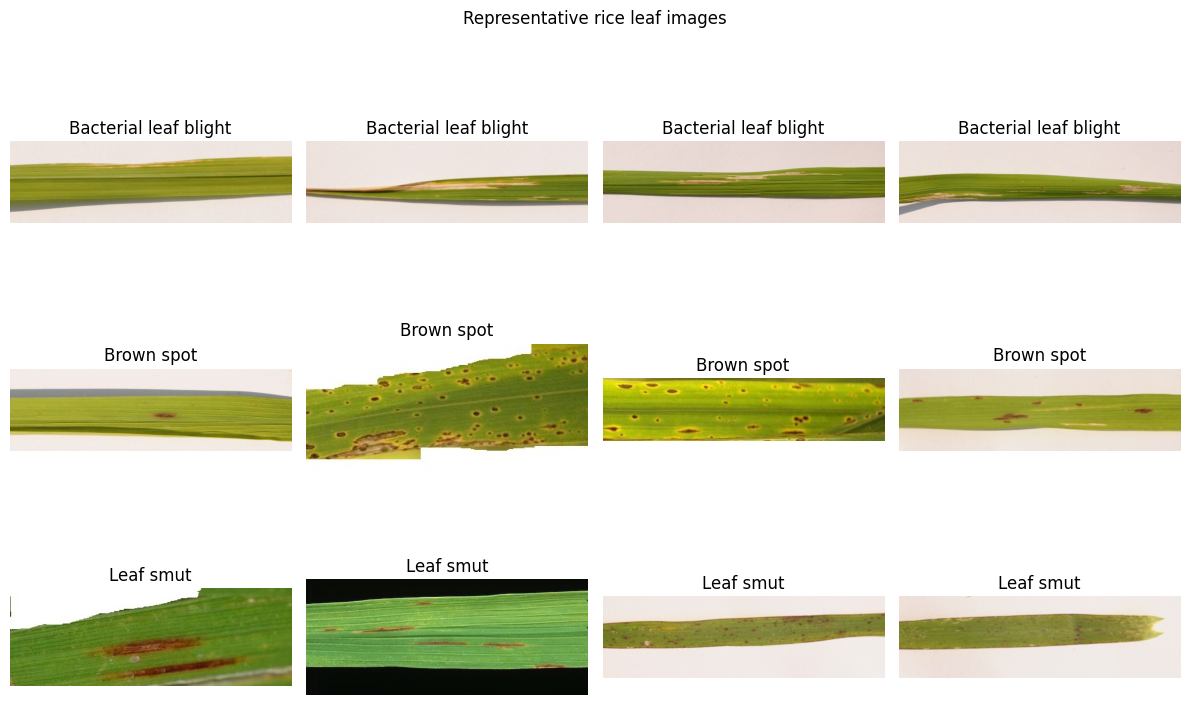

,image_count
class,
Bacterial leaf blight,40
Brown spot,40
Leaf smut,39


Class imbalance ratio (largest / smallest): 1.03


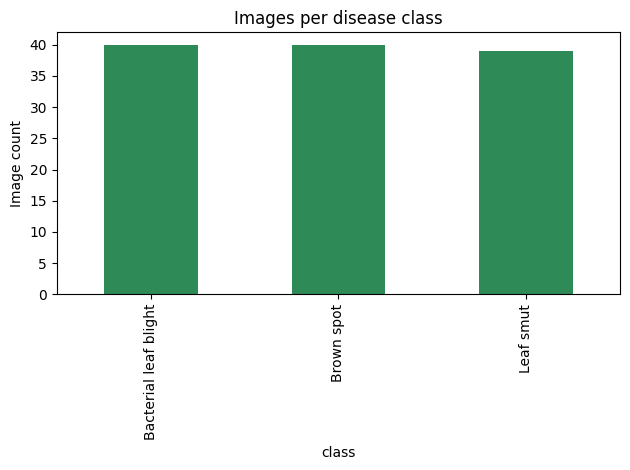

In [3]:
records = []
for path, label in zip(image_paths, labels):
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise ValueError(f"OpenCV could not decode image: {path}")
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    records.append({"path": path, "label": int(label), "class": class_names[int(label)],
                    "width": int(rgb.shape[1]), "height": int(rgb.shape[0]),
                    "mean_R": float(rgb[:, :, 0].mean()), "mean_G": float(rgb[:, :, 1].mean()),
                    "mean_B": float(rgb[:, :, 2].mean()), "mean_pixel": float(rgb.mean())})
eda = pd.DataFrame(records)
display(eda.groupby("class").agg(images=("path", "count"), mean_width=("width", "mean"),
                                 mean_height=("height", "mean"), mean_pixel=("mean_pixel", "mean")))
print("Expected per class from brief:", EXPECTED_IMAGES_PER_CLASS)
print("Observed class counts:\n", eda["class"].value_counts().sort_index())
print("\nImage dimensions (width x height):\n", eda.groupby(["width", "height"]).size().sort_values(ascending=False).head(10))
print("\nRGB mean values (0-255):\n", eda[["mean_R", "mean_G", "mean_B"]].describe().round(2))

fig, axes = plt.subplots(3, 4, figsize=(12, 8))
for class_index, ax_row in enumerate(axes):
    samples = eda[eda.label == class_index].sample(min(4, (eda.label == class_index).sum()), random_state=SEED)
    for ax, (_, row) in zip(ax_row, samples.iterrows()):
        image = cv2.cvtColor(cv2.imread(str(row.path)), cv2.COLOR_BGR2RGB)
        ax.imshow(image)
        ax.set_title(row["class"])
        ax.axis("off")
    for ax in ax_row[len(samples):]:
        ax.axis("off")
plt.suptitle("Representative rice leaf images")
plt.tight_layout()
plt.show()

count_table = eda["class"].value_counts().reindex(class_names)
display(count_table.rename("image_count").to_frame())
print("Class imbalance ratio (largest / smallest):", round(count_table.max() / count_table.min(), 2))
eda.to_csv(OUTPUT_DIR / "image_analysis.csv", index=False)
count_table.plot(kind="bar", color="seagreen", title="Images per disease class", ylabel="Image count")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "class_distribution.png", dpi=150)
plt.show()

## 3. Preprocessing and leakage-aware split

Images are decoded as RGB and resized consistently. A stratified 60/20/20 split is made **before** augmentation. Augmentation layers are only active during training; validation and test images remain unmodified. With only 40 source images per class, the held-out results will have substantial uncertainty.

In [4]:
X = np.empty((len(image_paths), *IMAGE_SIZE, 3), dtype=np.uint8)
for index, path in enumerate(image_paths):
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise ValueError(f"OpenCV could not decode image: {path}")
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    X[index] = cv2.resize(rgb, (IMAGE_SIZE[1], IMAGE_SIZE[0]), interpolation=cv2.INTER_AREA)
y = labels
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, stratify=y_train_val, random_state=SEED)
print("Train/validation/test:", len(y_train), len(y_val), len(y_test))
for name, split_labels in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(name, dict(zip(class_names, np.bincount(split_labels, minlength=len(class_names)))))

def make_dataset(images, targets, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((images, targets))
    if training:
        dataset = dataset.shuffle(len(targets), seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(BATCH_SIZE).prefetch(1)

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

Train/validation/test: 71 24 24
train {'Bacterial leaf blight': 24, 'Brown spot': 24, 'Leaf smut': 23}
validation {'Bacterial leaf blight': 8, 'Brown spot': 8, 'Leaf smut': 8}
test {'Bacterial leaf blight': 8, 'Brown spot': 8, 'Leaf smut': 8}


## 4. Data augmentation study

We compare the same compact CNN trained without augmentation and with modest on-the-fly horizontal/vertical flips, small rotations, zoom, and contrast changes. These transformations can reduce sensitivity to pose and illumination, but cannot create new biological diversity. Vertical flips and rotations may be inappropriate for some deployment settings; inspect the generated examples before relying on them.

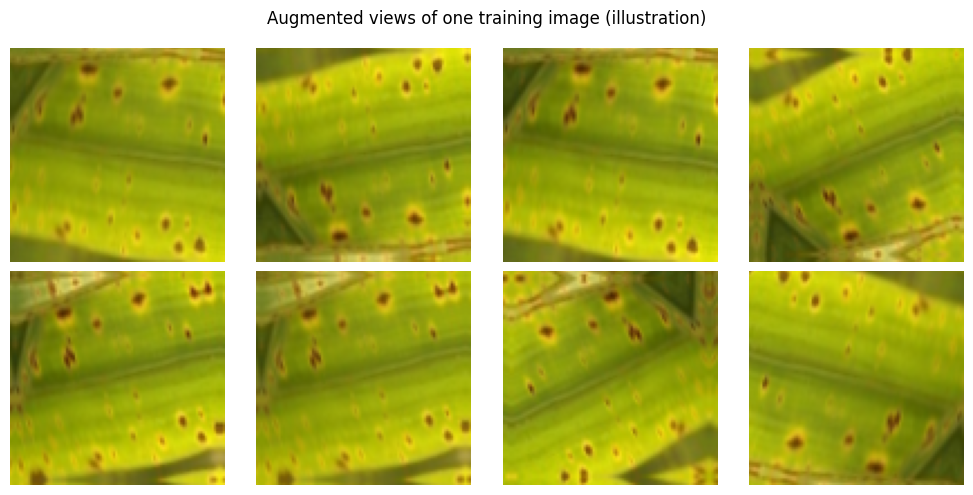

In [5]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    tf.keras.layers.RandomRotation(0.08, seed=SEED),
    tf.keras.layers.RandomZoom(0.10, seed=SEED),
    tf.keras.layers.RandomContrast(0.10, seed=SEED),
], name="training_augmentation")
sample_batch, _ = next(iter(make_dataset(X_train[:1], y_train[:1])))
augmented_samples = augmentation(tf.repeat(sample_batch, 8, axis=0), training=True)
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, image in zip(axes.flat, augmented_samples):
    ax.imshow(tf.clip_by_value(image / 255.0, 0, 1))
    ax.axis("off")
plt.suptitle("Augmented views of one training image (illustration)")
plt.tight_layout()
plt.show()

def build_cnn(use_augmentation=False):
    inputs = tf.keras.Input(shape=(*IMAGE_SIZE, 3))
    x = inputs
    if use_augmentation:
        x = augmentation(x)
    x = tf.keras.layers.Rescaling(1.0 / 255)(x)
    for filters in (32, 64, 128):
        x = tf.keras.layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.30)(x)
    outputs = tf.keras.layers.Dense(len(class_names), activation="softmax")(x)
    model = tf.keras.Model(inputs, outputs)
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def build_transfer_model():
    inputs = tf.keras.Input(shape=(*IMAGE_SIZE, 3))
    x = augmentation(inputs)
    x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
    base = tf.keras.applications.MobileNetV2(
        input_shape=(*IMAGE_SIZE, 3), include_top=False, weights="imagenet")
    base.trainable = False
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.30)(x)
    outputs = tf.keras.layers.Dense(len(class_names), activation="softmax")(x)
    model = tf.keras.Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


## 5. Train comparable models

All models use identical train/validation/test partitions and training budget. MobileNetV2 starts from ImageNet weights, freezes its feature extractor, and learns a small classification head. Its first run may download weights; errors are allowed to surface rather than silently substituting random weights.

In [6]:
model_builders = {
    "CNN - no augmentation": lambda: build_cnn(False),
    "CNN - augmentation": lambda: build_cnn(True),
    "MobileNetV2 - transfer + augmentation": build_transfer_model,
}
models, histories = {}, {}
for model_name, builder in model_builders.items():
    print(f"\nTraining: {model_name}")
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = builder()
    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=1)
    models[model_name] = model
    histories[model_name] = history.history
    safe_name = model_name.lower().replace(" ", "_").replace("-", "_").replace("+", "and")
    model.save(OUTPUT_DIR / f"{safe_name}.keras")
    pd.DataFrame(history.history).to_csv(OUTPUT_DIR / f"{safe_name}_history.csv", index=False)
print("Training complete. Models and histories saved in", OUTPUT_DIR)


Training: CNN - no augmentation


Epoch 1/3


 1/18 [>.............................] - ETA: 49s - loss: 1.1209 - accuracy: 0.0000e+00

 2/18 [==>...........................] - ETA: 2s - loss: 1.1144 - accuracy: 0.1250     

 3/18 [====>.........................] - ETA: 1s - loss: 1.1090 - accuracy: 0.1667

...

16/18 [=========================>....] - ETA: 0s - loss: 0.8128 - accuracy: 0.6250

17/18 [===========================>..] - ETA: 0s - loss: 0.7895 - accuracy: 0.6324

18/18 [==============================] - ETA: 0s - loss: 0.7670 - accuracy: 0.6479

18/18 [==============================] - 2s 109ms/step - loss: 0.7670 - accuracy: 0.6479 - val_loss: 0.5503 - val_accuracy: 0.7917


Training complete. Models and histories saved in outputs


## 6. Evaluate once on the untouched test set

Macro-averaged metrics give each class equal weight. The per-class report and confusion matrices expose errors hidden by aggregate accuracy. Because the test set contains very few images per class, a single changed prediction can move the metrics substantially.


 CNN - no augmentation 

                       precision    recall  f1-score   support

Bacterial leaf blight       0.00      0.00      0.00         8
           Brown spot       0.33      1.00      0.50         8
            Leaf smut       0.00      0.00      0.00         8

             accuracy                           0.33        24
            macro avg       0.11      0.33      0.17        24
         weighted avg       0.11      0.33      0.17        24



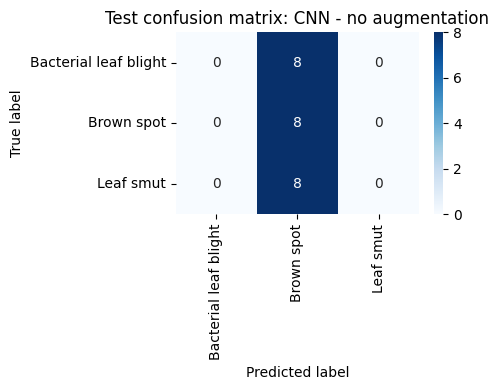


 CNN - augmentation 

                       precision    recall  f1-score   support

Bacterial leaf blight       0.00      0.00      0.00         8
           Brown spot       0.33      1.00      0.50         8
            Leaf smut       0.00      0.00      0.00         8

             accuracy                           0.33        24
            macro avg       0.11      0.33      0.17        24
         weighted avg       0.11      0.33      0.17        24



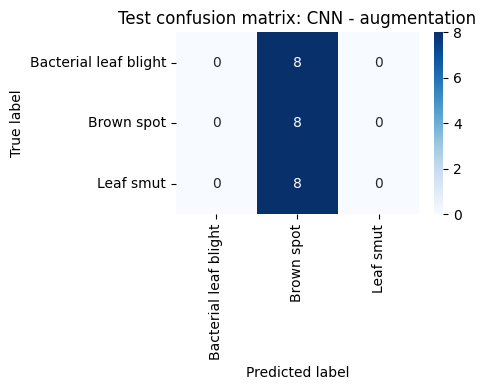


 MobileNetV2 - transfer + augmentation 

                       precision    recall  f1-score   support

Bacterial leaf blight       0.70      0.88      0.78         8
           Brown spot       0.88      0.88      0.88         8
            Leaf smut       0.83      0.62      0.71         8

             accuracy                           0.79        24
            macro avg       0.80      0.79      0.79        24
         weighted avg       0.80      0.79      0.79        24



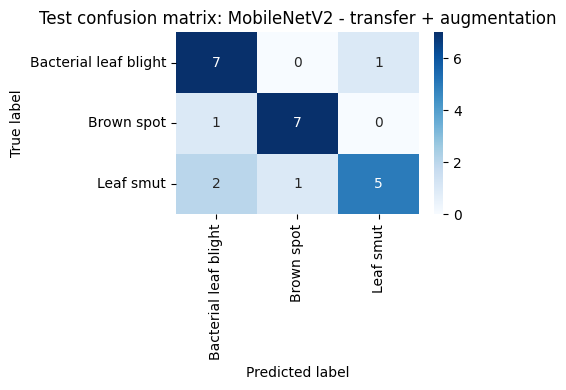

,model,accuracy,macro_precision,macro_recall,macro_f1
0,MobileNetV2 - transfer + augmentation,0.7917,0.8028,0.7917,0.7890
1,CNN - no augmentation,0.3333,0.1111,0.3333,0.1667
2,CNN - augmentation,0.3333,0.1111,0.3333,0.1667


Saved test metrics to outputs\model_comparison.csv


In [7]:
results = []
predictions = {}
for model_name, model in models.items():
    probabilities = model.predict(test_ds, verbose=0)
    predicted = probabilities.argmax(axis=1)
    predictions[model_name] = predicted
    metrics = {
        "model": model_name,
        "accuracy": accuracy_score(y_test, predicted),
        "macro_precision": precision_score(y_test, predicted, average="macro", zero_division=0),
        "macro_recall": recall_score(y_test, predicted, average="macro", zero_division=0),
        "macro_f1": f1_score(y_test, predicted, average="macro", zero_division=0),
    }
    results.append(metrics)
    print("\n", model_name, "\n")
    print(classification_report(y_test, predicted, labels=range(len(class_names)),
                                target_names=class_names, zero_division=0))
    cm = confusion_matrix(y_test, predicted, labels=range(len(class_names)))
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"Test confusion matrix: {model_name}")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / (model_name.lower().replace(" ", "_").replace("-", "_").replace("+", "and") + "_confusion.png"), dpi=150)
    plt.show()

results_df = pd.DataFrame(results).sort_values("macro_f1", ascending=False).reset_index(drop=True)
display(results_df.round(4))
results_df.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
print("Saved test metrics to", OUTPUT_DIR / "model_comparison.csv")

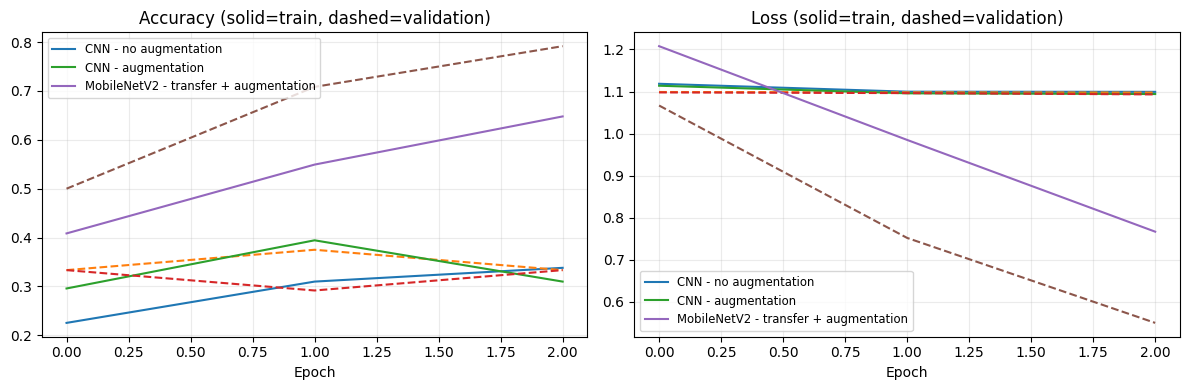

Measured best on this held-out split by macro-F1: MobileNetV2 - transfer + augmentation (macro-F1=0.789).
This is a small exploratory comparison, not reliable evidence of production performance.
Saved model comparison and training curves in: C:\Users\HP\RiceLeaf disease detection\outputs


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for model_name, history in histories.items():
    axes[0].plot(history["accuracy"], label=model_name)
    axes[0].plot(history["val_accuracy"], linestyle="--")
    axes[1].plot(history["loss"], label=model_name)
    axes[1].plot(history["val_loss"], linestyle="--")
axes[0].set_title("Accuracy (solid=train, dashed=validation)")
axes[1].set_title("Loss (solid=train, dashed=validation)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend(fontsize="small")
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=150)
plt.show()

best_model_name = results_df.iloc[0]["model"]
best_f1 = float(results_df.iloc[0]["macro_f1"])
print(f"Measured best on this held-out split by macro-F1: {best_model_name} (macro-F1={best_f1:.3f}).")
print("This is a small exploratory comparison, not reliable evidence of production performance.")
print("Saved model comparison and training curves in:", OUTPUT_DIR.resolve())

## 7. Model comparison and recommendation

The table above is computed from this run; no performance values are pre-filled or fabricated. Prefer the model with the strongest macro-F1 only if its per-class errors and validation behavior are also acceptable. In case of close scores, favor the simpler model until a larger, independently collected dataset can settle the comparison.

**Production recommendation:** do not deploy any of these models as a standalone diagnosis tool based on this dataset. Treat the measured winner as a candidate for a larger, field-representative evaluation. Collect diverse leaves, farms, devices, lighting and disease severity; obtain expert-verified labels; reserve group-wise external test data; and report confidence intervals and failure modes.

## 8. Challenges, techniques, and rationale

| Challenge | Technique used | Rationale / remaining risk |
|---|---|---|
| Only 120 images (40 per stated class) | Frozen ImageNet MobileNetV2 feature extractor, a small CNN baseline, and short, matched training runs | Transfer learning can reuse generic visual features, but these sample counts cannot establish field performance. |
| The brief's introductory wording says leaf blast, but its class list says Leaf smut, Brown spot, and Bacterial leaf blight | Discover labels from folders and print them; check actual counts against 40/class | Avoids silently assigning incorrect labels; confirm the archive's labels with the project owner/domain expert. |
| Overfitting risk | Dropout, validation split, conservative augmentation, frozen pretrained backbone | Validation data is also tiny and may not represent deployment conditions. |
| Artificially inflating evaluation | Stratify and split original files before on-the-fly augmentation; keep test data untouched | Prevents transformed copies of a training image leaking into evaluation; duplicates already present in the source dataset remain a possible risk. |
| Class imbalance or missing/corrupt images | Count classes and fail visibly on invalid or unreadable images; report macro metrics | Does not impute missing data; investigate and correct source files instead. |
| Limited diversity of transformations | Modest geometric and contrast augmentation; inspect sample transformations | Augmentation cannot substitute for more independent field images, and some transforms may alter meaningful cues. |
| Small held-out test set | Per-class report, confusion matrices and explicit uncertainty caveat | Metrics are noisy; repeated tuning on this test split would invalidate it. Use a separate external test set for serious claims. |
| Runtime and external dependencies | Configurable image size/batch/epochs, CPU-compatible models, explicit download steps | ImageNet weights and dataset require initial internet access; compute time varies by hardware. |

### Suggested next steps
1. Verify class definitions and label quality with a rice-disease specialist.
2. Expand to hundreds or thousands of independently sourced, expert-labeled images per class across locations and conditions.
3. Split by plant, farm, or capture session to avoid near-duplicate leakage; keep an external test set untouched until final evaluation.
4. Compare repeated stratified/grouped runs, confidence intervals, calibration, and per-class error costs before deciding on deployment.
5. Obtain human oversight and communicate uncertainty; this notebook is educational research, not agricultural diagnostic advice.